# Mental Health Risk Prediction - Notebook modulaire

## 1 - Environnement et imports

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src.config import (DATA_PATH, MODEL_PATH, TARGET, NUMERIC_COLS, NOMINAL_COLS, ORDINAL_COLS, OTHER_NOMINAL_COLS, ORDINAL_CATEGORIES)
from src.data_loader import load_data_frame, split_data
from src.eda import (missing_values_report, duplicate_count,invalid_values_report, iqr_outlier_report, figure_scatterplot)
from src.preprocessing import generate_preprocessor
from src.training import get_models, train_model
from src.evaluation import evaluate_model, error_analysis
from src.optimization import optimize_models, choose_best_model, PARAM_GRIDS
from src.persistence import save_model, load_model
from src.transforms import SocialMediaCapper

sns.set_theme(style="whitegrid")

# Étape 1 - Chargement et analyse exploratoire (EDA)

### 1.1 - Charger le dataset et examiner sa structure

In [2]:
df = load_data_frame(DATA_PATH)
print(f"Lignes : {df.shape[0]} | Colonnes : {df.shape[1]}")

display(df.head())
display(df.dtypes.to_frame("type"))

Lignes : 2000 | Colonnes : 17


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


,type
Student_ID,str
Age,int64
Gender,str
Year_of_Study,int64
Sleep_Hours,float64
Study_Hours_Per_Week,float64
GPA,float64
Social_Media_Hours,float64
Screen_Time_Hours,float64
Physical_Activity,str


### 1.2 - Identifier les valeurs des variables catégorielles

In [3]:
CAT_COLS = NOMINAL_COLS + OTHER_NOMINAL_COLS + ORDINAL_COLS

for col in CAT_COLS:
    print(f"\n{col} :")
    display(
        df[col].value_counts(dropna=False).to_frame("effectif")
    )

print("Ordre ordinal configuré :", dict(zip(ORDINAL_COLS, ORDINAL_CATEGORIES)))


Gender :


,effectif
Gender,
Female,971
Male,932
Non-binary,97



Part_Time_Job :


,effectif
Part_Time_Job,
No,1289
Yes,711



Previous_Mental_Health_History :


,effectif
Previous_Mental_Health_History,
No,1408
Yes,592


... (3 outputs left out)

,effectif
Physical_Activity,
Moderate,906
Low,679
High,415



Diet_Quality :


,effectif
Diet_Quality,
Average,860
Poor,587
Good,484
NaN,69


Ordre ordinal configuré : {'Physical_Activity': ['Low', 'Moderate', 'High'], 'Diet_Quality': ['Poor', 'Average', 'Good']}


### 1.3 - Qualité : valeurs manquantes, doublons, incohérences et outliers

In [4]:
print("Valeurs manquentes:")
display(
    missing_values_report(df)
    .sort_values("percent", ascending=False)
)

# invalid values
display(invalid_values_report(df))

print("Doublons complets :", duplicate_count(df))

print("valeurs outlier")
display(iqr_outlier_report(df, NUMERIC_COLS))

Valeurs manquentes:


,count,percent
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90
Student_ID,0,0.00
Age,0,0.00
Screen_Time_Hours,0,0.00


,column,sum
0,Age,0
1,Sleep_Hours,0
2,Study_Hours_Per_Week,0
3,Social_Media_Hours,0
4,Screen_Time_Hours,0
5,Attendance_Rate,0


Doublons complets : 0
valeurs outlier


,column,outliers,lower,upper
0,Age,4,15.5000,27.5000
1,Sleep_Hours,2,3.6000,10.0000
2,Study_Hours_Per_Week,7,4.0000,36.0000
3,GPA,9,1.6150,3.4950
4,Social_Media_Hours,20,3.0125,8.9125
5,Screen_Time_Hours,7,3.9500,13.1500
6,Financial_Stress,0,0.1500,11.7500
7,Family_Support,0,0.7500,12.3500
8,Attendance_Rate,12,65.7500,104.5500


### 1.4 - Statistiques descriptives et distribution de la cible

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


Répartition de la cible :


,effectif,pourcentage
Mental_Health_Risk,,
High,680,34.0
Medium,660,33.0
Low,660,33.0


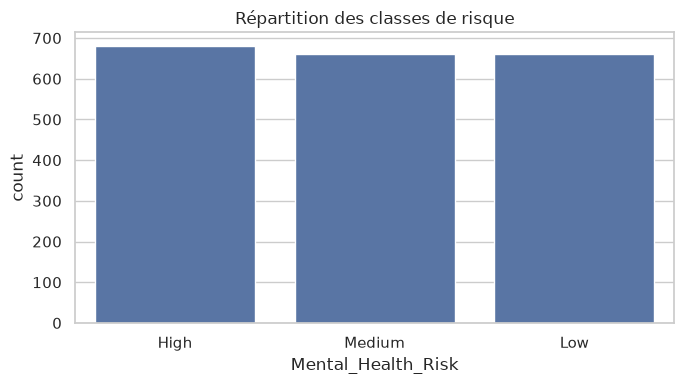

In [5]:
display(df[NUMERIC_COLS].describe().T) # Transpose

print("Répartition de la cible :")
display(pd.DataFrame({
    "effectif": df[TARGET].value_counts(),
    "pourcentage": df[TARGET].value_counts(normalize=True) * 100
}))

# Visualisation (count plot)
_, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x=TARGET, ax=ax)
ax.set_title("Répartition des classes de risque")
plt.tight_layout()
plt.show()

### 1.5 - Analyse univariée : variables numériques et catégorielles

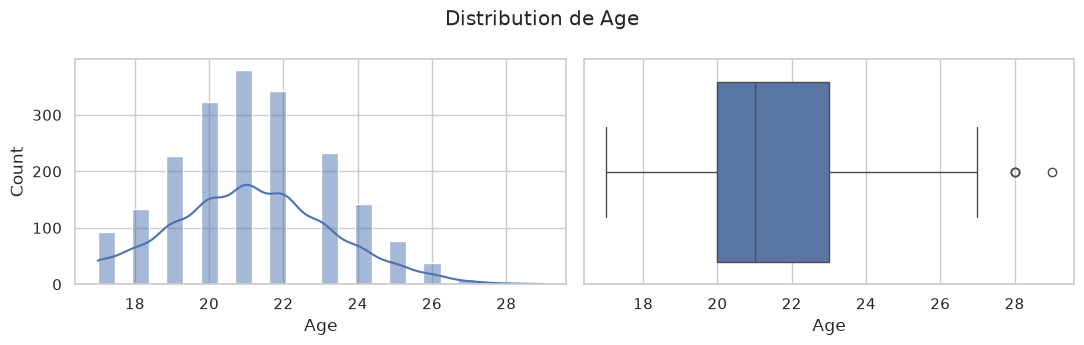

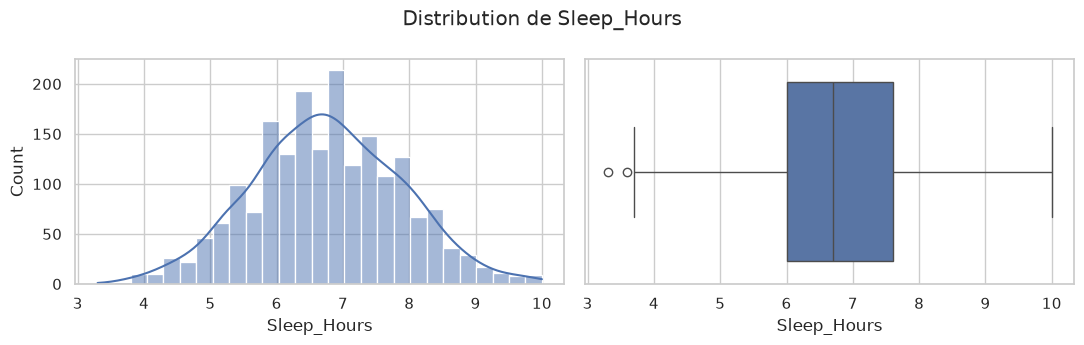

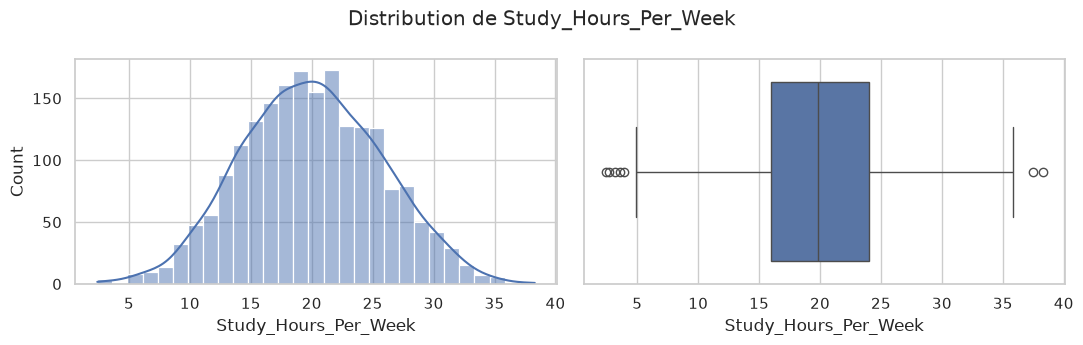

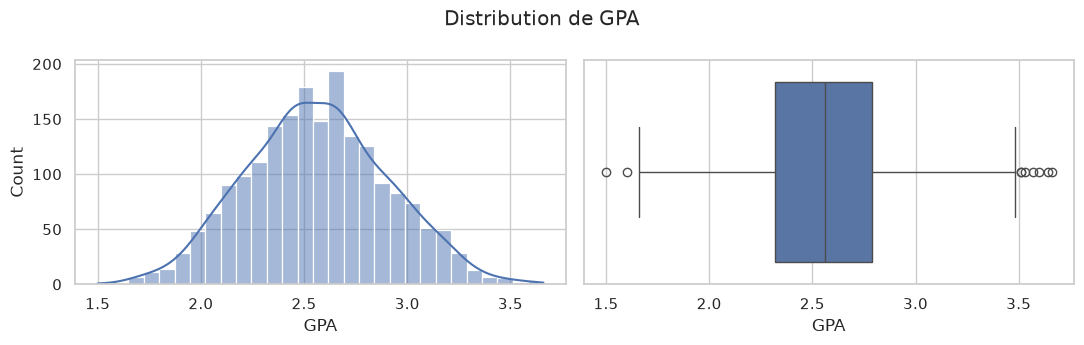

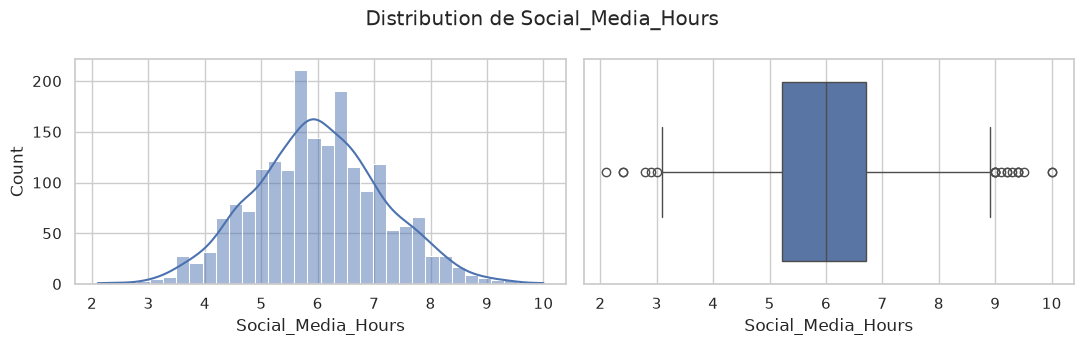

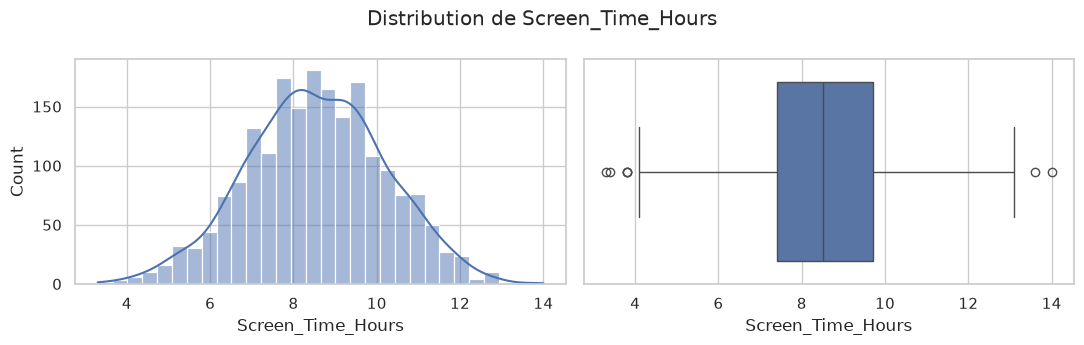

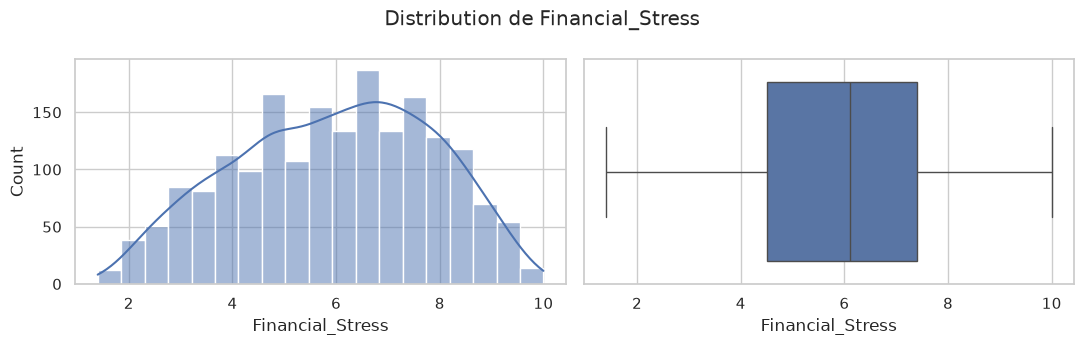

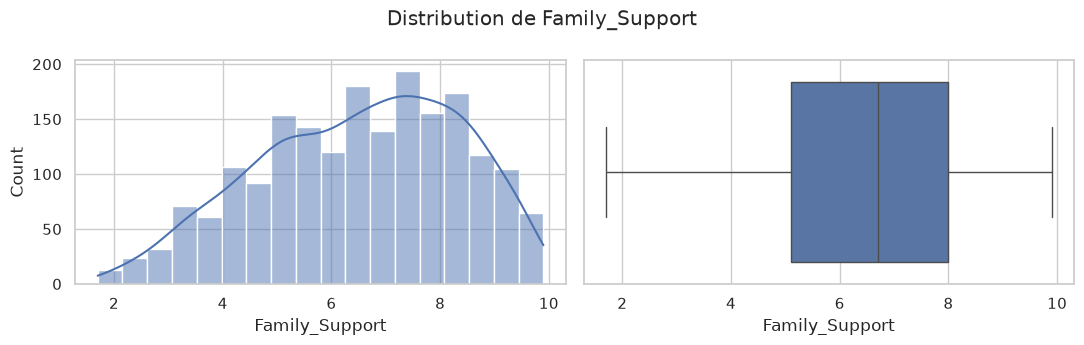

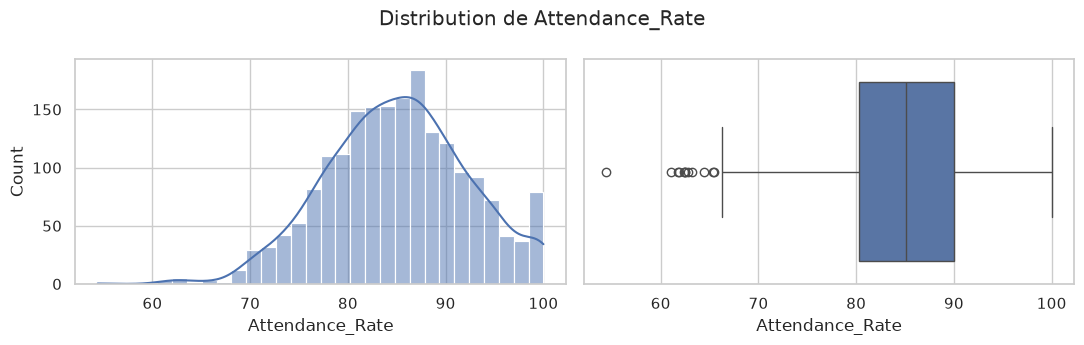

In [6]:
for col in NUMERIC_COLS:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    sns.histplot(data=df, x=col, kde=True, ax=axes[0])
    sns.boxplot(data=df, x=col, ax=axes[1])
    fig.suptitle(f"Distribution de {col}")
    plt.tight_layout()
    plt.show()

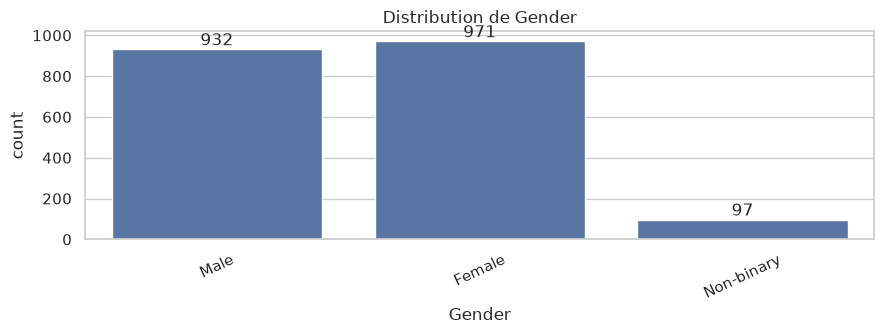

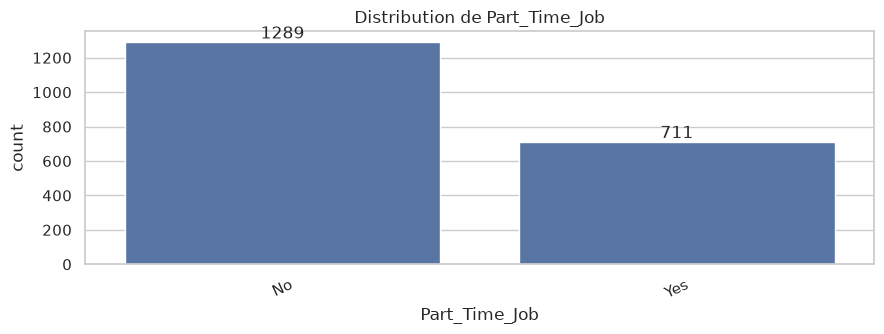

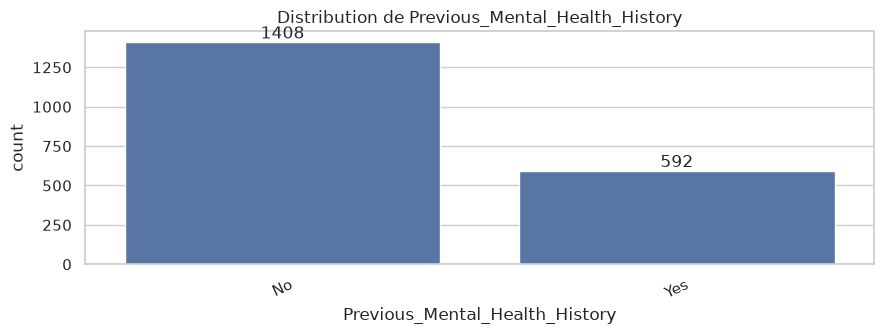

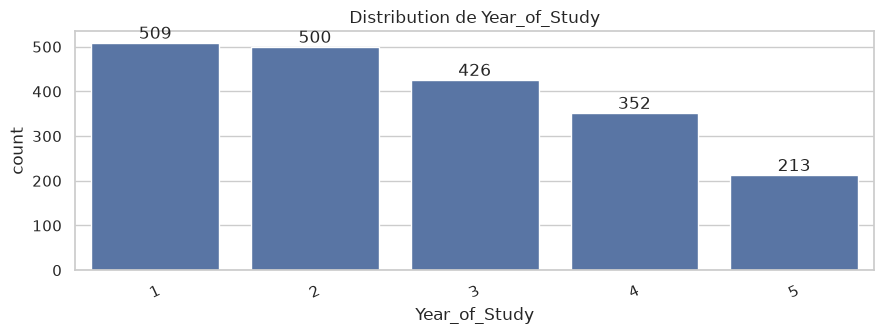

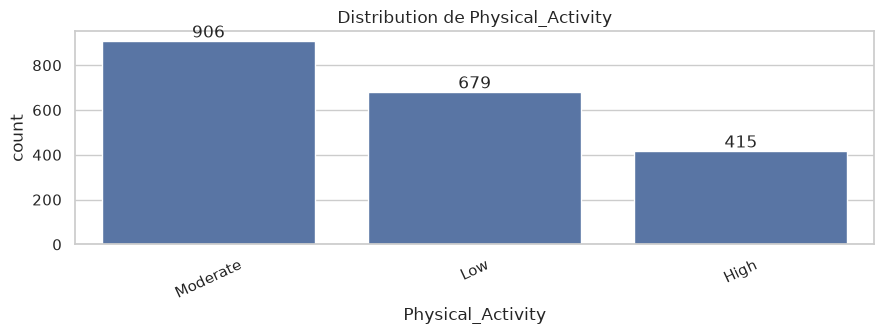

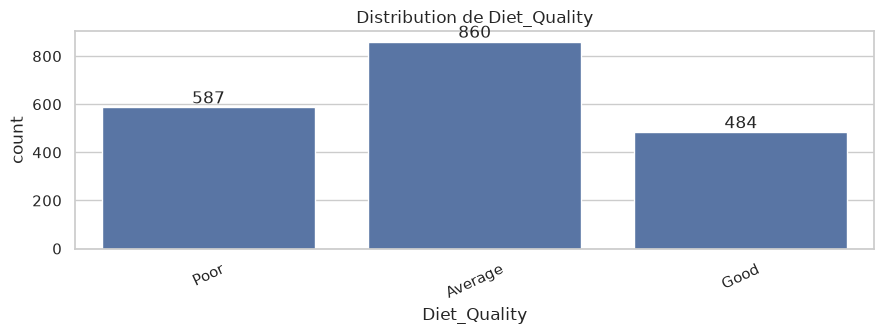

In [7]:
for col in CAT_COLS:
    fig, ax = plt.subplots(figsize=(9, 3.5))
    axe = sns.countplot(data=df, x=col, ax=ax)

    # afficher les count dans lesbars
    for container in axe.containers:
        axe.bar_label(container)

    ax.set_title(f"Distribution de {col}")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()

### 1.6 - Relations avec la variable cible et corrélations

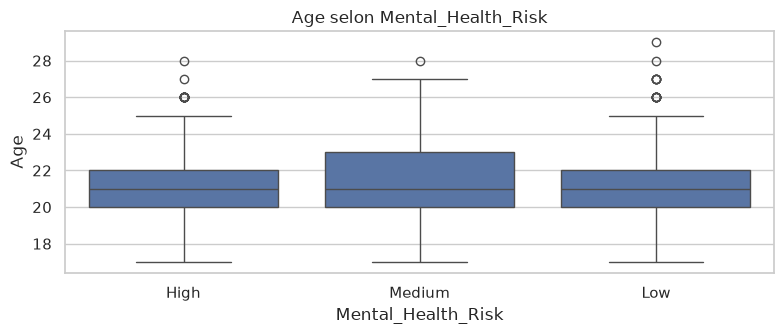

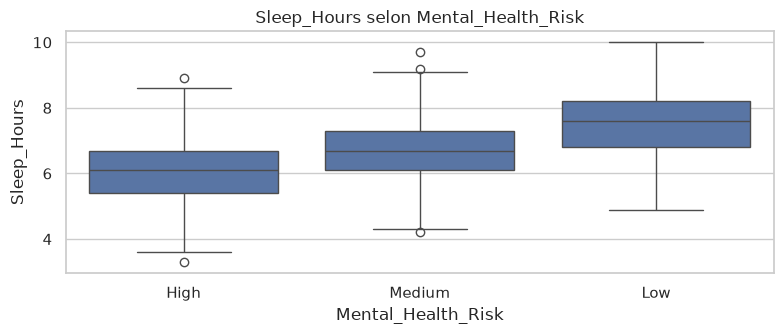

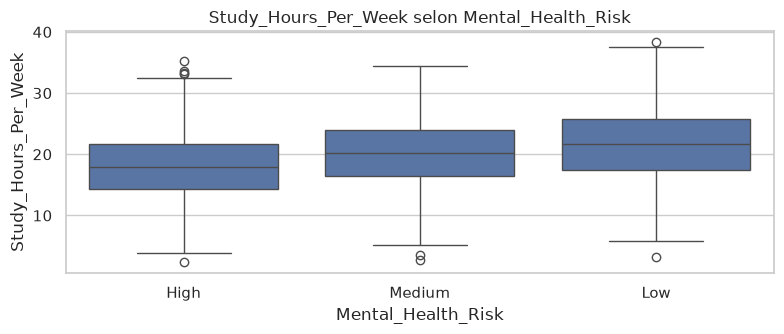

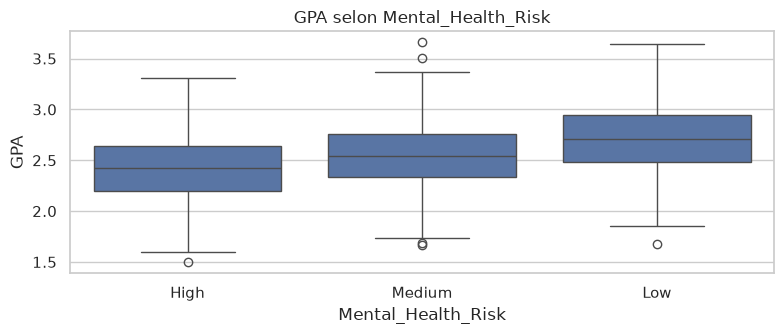

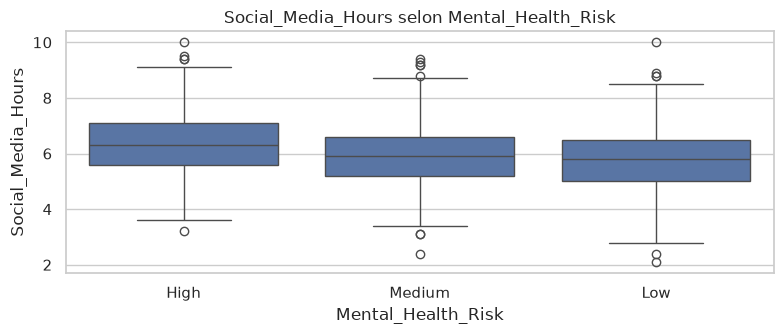

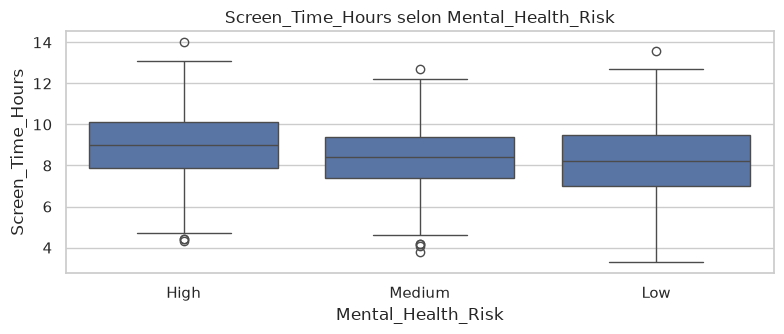

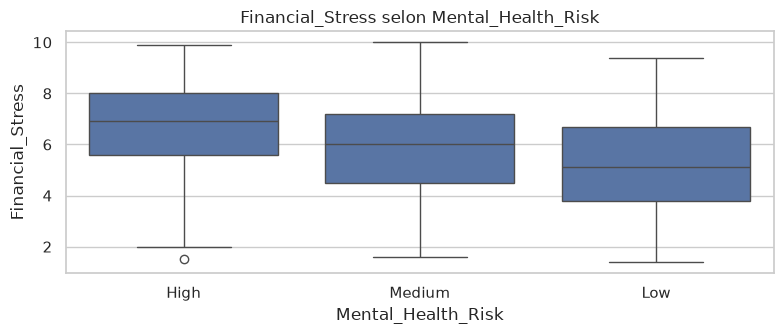

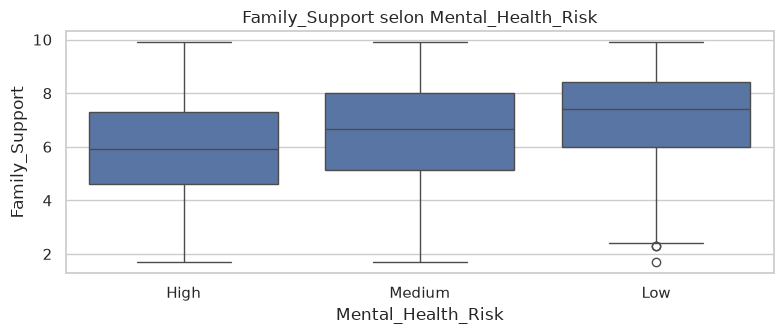

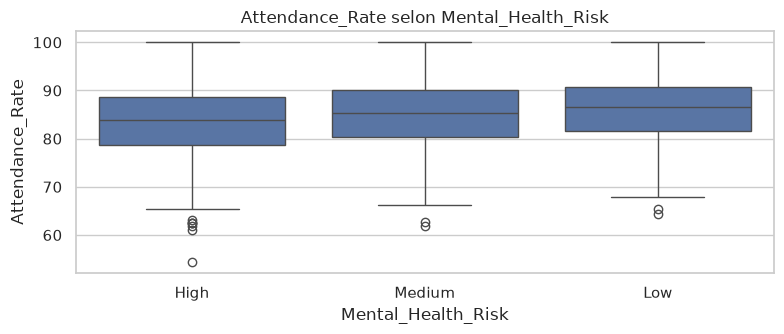

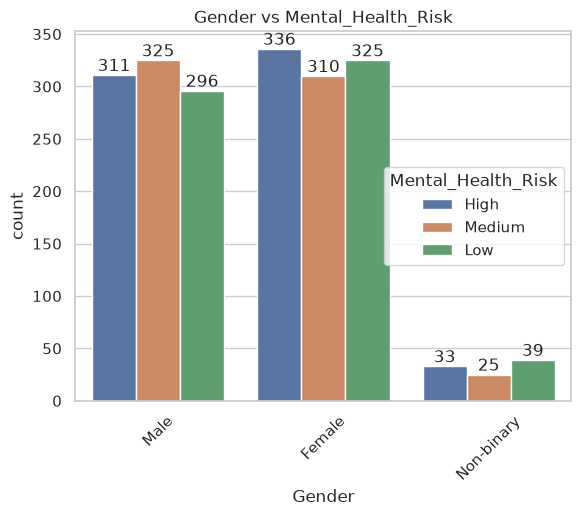

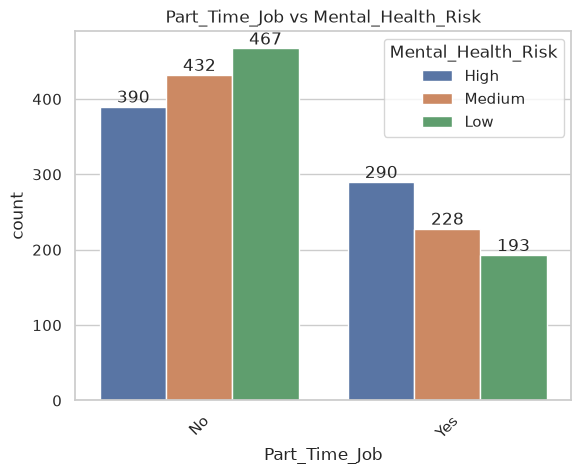

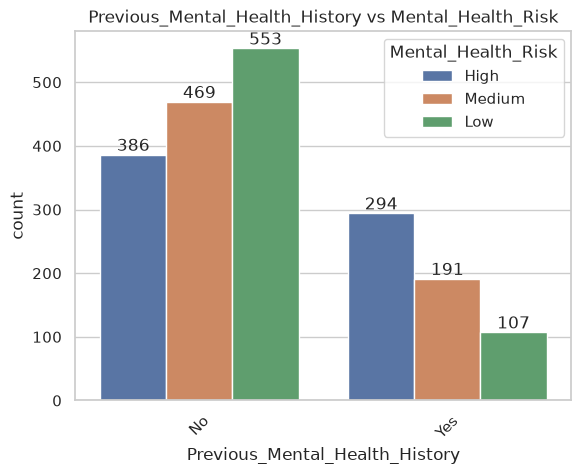

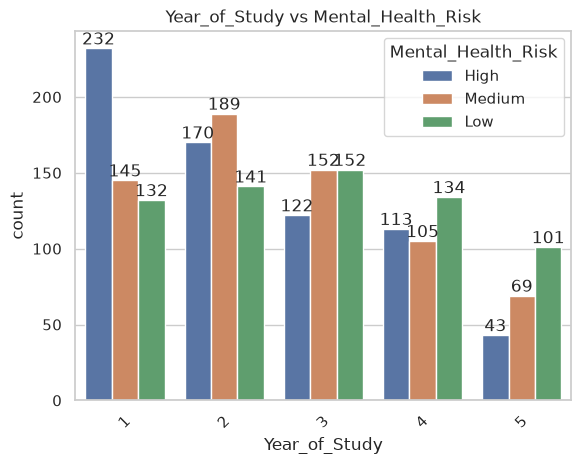

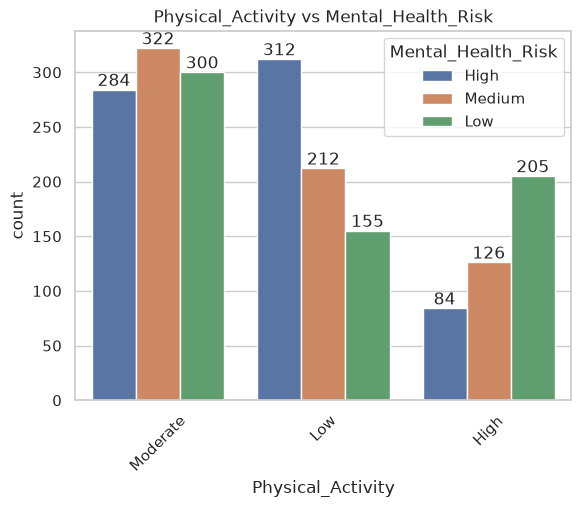

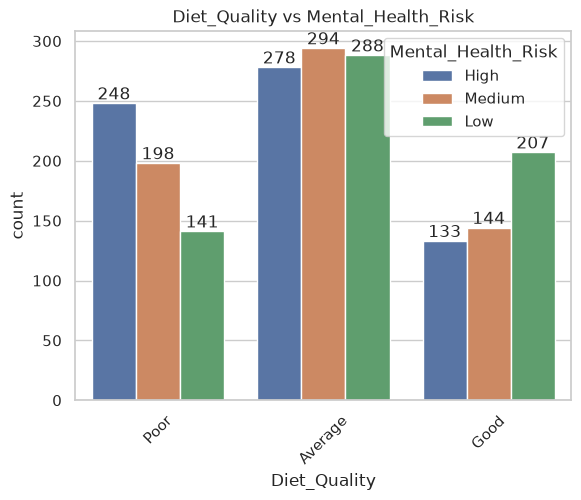

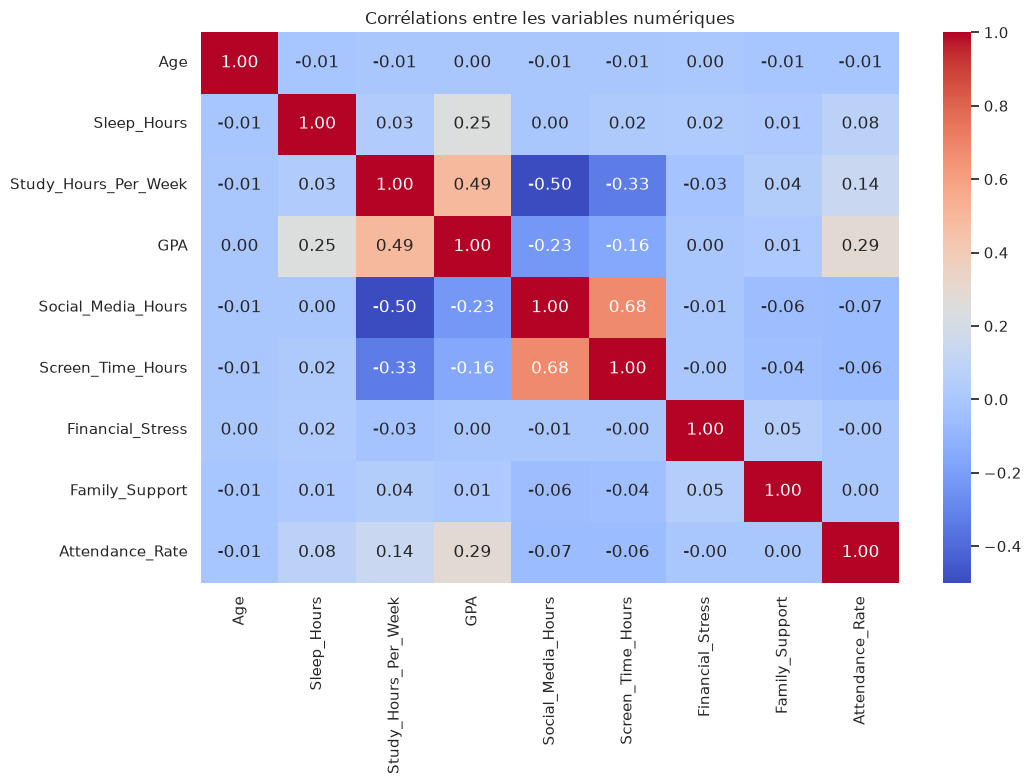

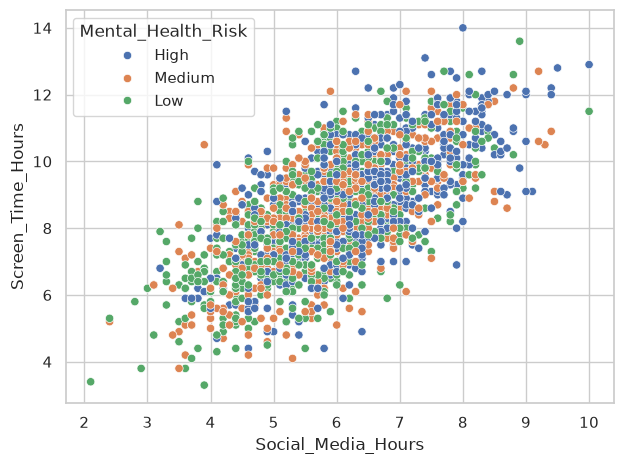

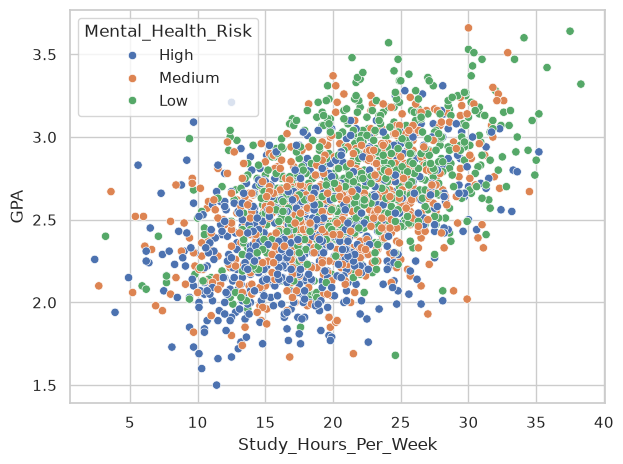

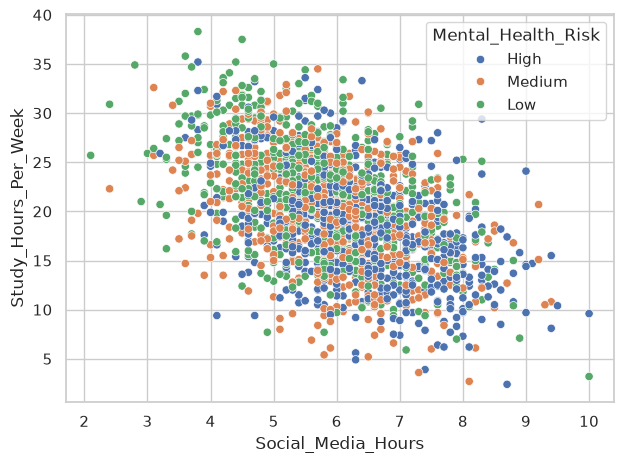

In [8]:
# Numeric colons
for col in NUMERIC_COLS:
    fig, ax = plt.subplots(figsize=(8, 3.5))
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax)
    ax.set_title(f"{col} selon {TARGET}")
    plt.tight_layout()
    plt.show()

# Categorial colons
for col in CAT_COLS:
    axe = sns.countplot(data=df, x=col, hue=TARGET)

    # Afficher les counts dans bars
    for c in axe.containers:
        axe.bar_label(c)

    plt.title(f"{col} vs {TARGET}")
    plt.xticks(rotation=45)
    plt.show()

# Corrlation
plt.figure(figsize=(11, 8))
sns.heatmap(df[NUMERIC_COLS].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Corrélations entre les variables numériques")
plt.tight_layout()
plt.show()

# Afficher les relarion tres forte
figure_scatterplot(df, x="Social_Media_Hours", y="Screen_Time_Hours")

figure_scatterplot(df, x="Study_Hours_Per_Week", y="GPA")

figure_scatterplot(df, x="Social_Media_Hours", y="Study_Hours_Per_Week")

# Étape 2 — Transformation et préparation des données

### 2.1 - Séparer train/test

In [9]:
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2)

print("Train :", X_train.shape, "| Test :", X_test.shape)

print("\nPart de chaque classe dans le train :")
display(y_train.value_counts(normalize=True).to_frame('%'))

print("\nPart de chaque classe dans le test :")
display(y_test.value_counts(normalize=True).to_frame('%'))

Train : (1600, 15) | Test : (400, 15)

Part de chaque classe dans le train :


,%
Mental_Health_Risk,
High,0.34
Medium,0.33
Low,0.33



Part de chaque classe dans le test :


,%
Mental_Health_Risk,
High,0.34
Low,0.33
Medium,0.33


### 2.2 - Contrôler la correction métier (Social_Media_Hours)

In [10]:
X_train_checked = SocialMediaCapper().transform(X_train)

before = (X_train["Social_Media_Hours"] > X_train["Screen_Time_Hours"]).sum()
after = (X_train_checked["Social_Media_Hours"] > X_train_checked["Screen_Time_Hours"]).sum()
print(f"Valeurs incohérentes : avant={before}, après={after}")

Valeurs incohérentes : avant=31, après=0


### 2.3 - Construire et examiner le prétraitement

In [11]:
preprocessor = generate_preprocessor(is_apply_scaler=True)

print(preprocessor)
print("Colonnes numériques :", NUMERIC_COLS)
print("Colonnes nominales :", NOMINAL_COLS)
print("Colonnes ordinales :", ORDINAL_COLS)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('outliers', IQRCapper()),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'Sleep_Hours', 'Study_Hours_Per_Week',
                                  'GPA', 'Social_Media_Hours',
                                  'Screen_Time_Hours', 'Financial_Stress',
                                  'Family_Support', 'Attendance_Rate']),
                                ('nom',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(...
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Gender', 'Part_Time_Job',
                                  'Previous

# Étape 3 - Entraînement et comparaison des modèles

### 3.1 - Construire les modèles

In [12]:
models = get_models()
for name, pipeline in models.items():
    print(f"{name} : {pipeline.named_steps['classifier']}")

Logistic Regression : LogisticRegression(max_iter=1000)
KNN : KNeighborsClassifier()
Random Forest : RandomForestClassifier(random_state=26)


### 3.2 - Entraîner models sans validation croisée


=== Logistic Regression ===
              precision    recall  f1-score   support

        High       0.80      0.77      0.78       136
         Low       0.84      0.82      0.83       132
      Medium       0.62      0.66      0.64       132

    accuracy                           0.75       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.75      0.75      0.75       400



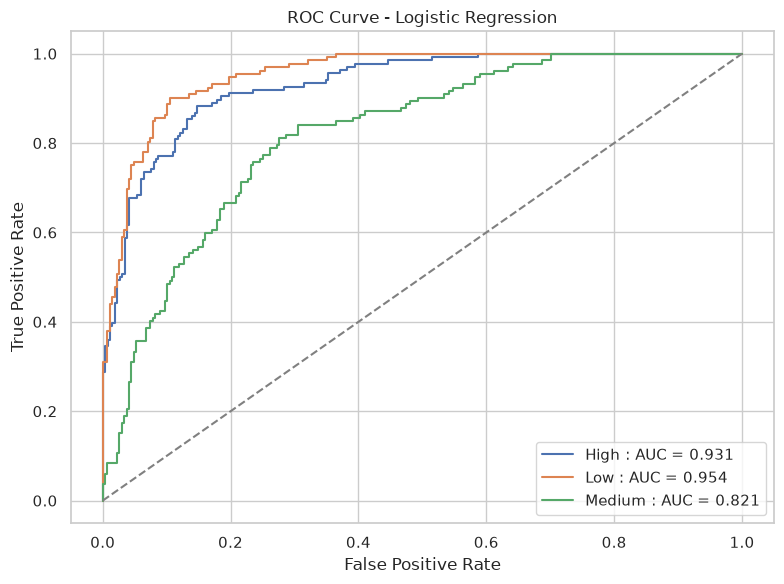

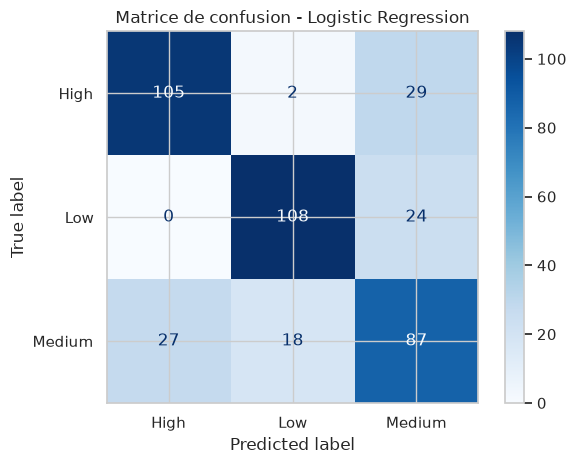


=== KNN ===
              precision    recall  f1-score   support

        High       0.67      0.64      0.66       136
         Low       0.64      0.69      0.66       132
      Medium       0.46      0.45      0.45       132

    accuracy                           0.59       400
   macro avg       0.59      0.59      0.59       400
weighted avg       0.59      0.59      0.59       400



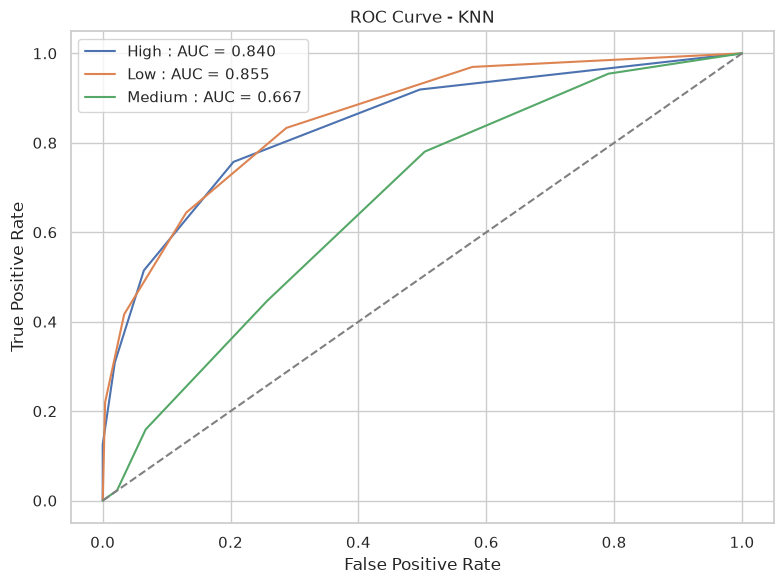

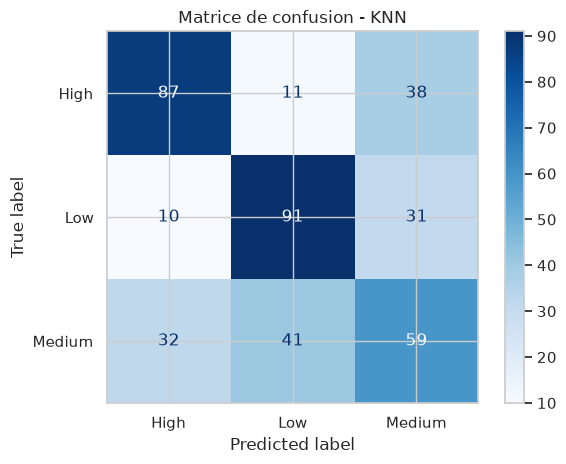


=== Random Forest ===
              precision    recall  f1-score   support

        High       0.73      0.71      0.72       136
         Low       0.73      0.78      0.75       132
      Medium       0.55      0.53      0.54       132

    accuracy                           0.67       400
   macro avg       0.67      0.67      0.67       400
weighted avg       0.67      0.67      0.67       400



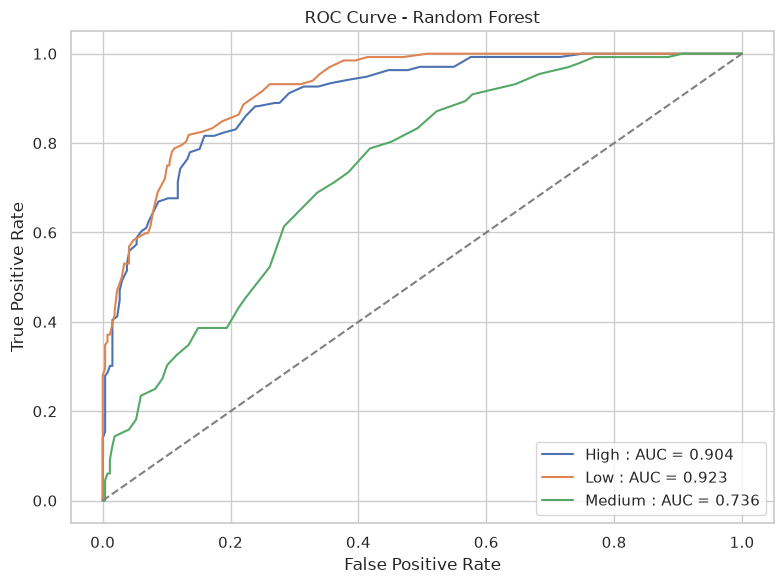

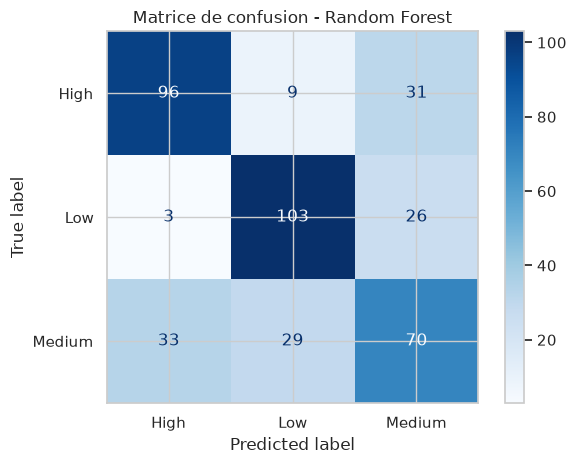

In [18]:
mitrix_rows = []
for name, pipeline in models.items():
    train_model(pipeline, X_train, y_train)
    mitrix_rows.append(
        evaluate_model(name, pipeline, X_test, y_test)
    )

cv_df = pd.DataFrame(mitrix_rows).sort_values("F1-score", ascending=False)

### 3.3 - Comparer visuellement les modèles

,model,Accuracy,Precision,Recall,F1-score,ROC_AUC
0,Logistic Regression,0.7500,0.753544,0.749777,0.751352,0.901925
2,Random Forest,0.6725,0.669650,0.672163,0.670512,0.854446
1,KNN,0.5925,0.590573,0.592023,0.590756,0.787050


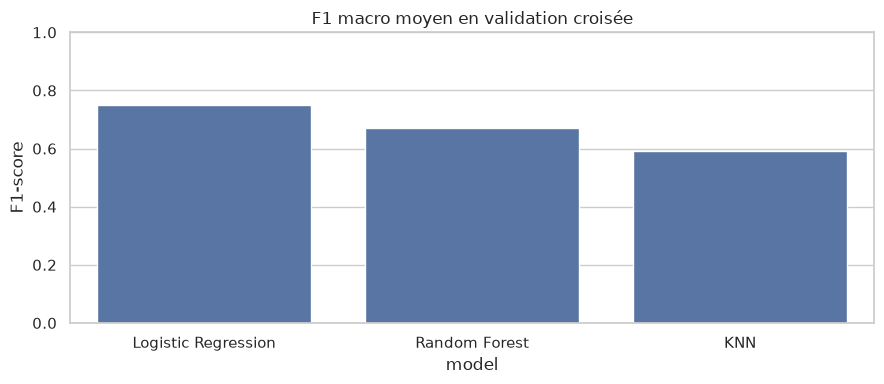

In [20]:
# table
display(cv_df)

# graph
plt.figure(figsize=(9, 4))
sns.barplot(data=cv_df, x="model", y="F1-score")
plt.title("F1 macro moyen en validation croisée")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Étape 4 - Optimisation, évaluation finale et sauvegarde

### 4.1 - Consulter les grilles d'hyperparamètres

In [21]:
for name, params in PARAM_GRIDS.items():
    print(f"\n{name} : {params}")


Logistic Regression : {'classifier__C': [0.1, 1, 10], 'classifier__class_weight': [None, 'balanced']}

KNN : {'classifier__n_neighbors': [3, 5, 7, 9, 11], 'classifier__weights': ['uniform', 'distance'], 'classifier__metric': ['euclidean', 'manhattan']}

Random Forest : {'classifier__n_estimators': [100, 200], 'classifier__max_depth': [5, 10, None]}


### 4.2 - Optimiser avec GridSearchCV

In [22]:
tuned = optimize_models(X_train, y_train, cv=5)

optimized_results = pd.DataFrame([
    {"Model": name, "F1_CV": grid.best_score_, "Params": grid.best_params_} for name, grid in tuned.items()
]).sort_values("F1_CV", ascending=False)

display(optimized_results)

best_name, best_model = choose_best_model(tuned)

print("Modèle retenu :", best_name)

Logistic Regression: best F1 CV=0.760; params={'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
KNN: best F1 CV=0.649; params={'classifier__metric': 'euclidean', 'classifier__n_neighbors': 11, 'classifier__weights': 'distance'}
Random Forest: best F1 CV=0.682; params={'classifier__max_depth': 10, 'classifier__n_estimators': 200}


,Model,F1_CV,Params
0,Logistic Regression,0.759969,"{'classifier__C': 0.1, 'classifier__class_weig..."
2,Random Forest,0.682179,"{'classifier__max_depth': 10, 'classifier__n_e..."
1,KNN,0.649121,"{'classifier__metric': 'euclidean', 'classifie..."


Modèle retenu : Logistic Regression


### 4.3 - Évaluer **une seule fois** sur le test indépendant


=== Logistic Regression ===
              precision    recall  f1-score   support

        High       0.81      0.76      0.78       136
         Low       0.83      0.83      0.83       132
      Medium       0.62      0.66      0.64       132

    accuracy                           0.75       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.75      0.75      0.75       400



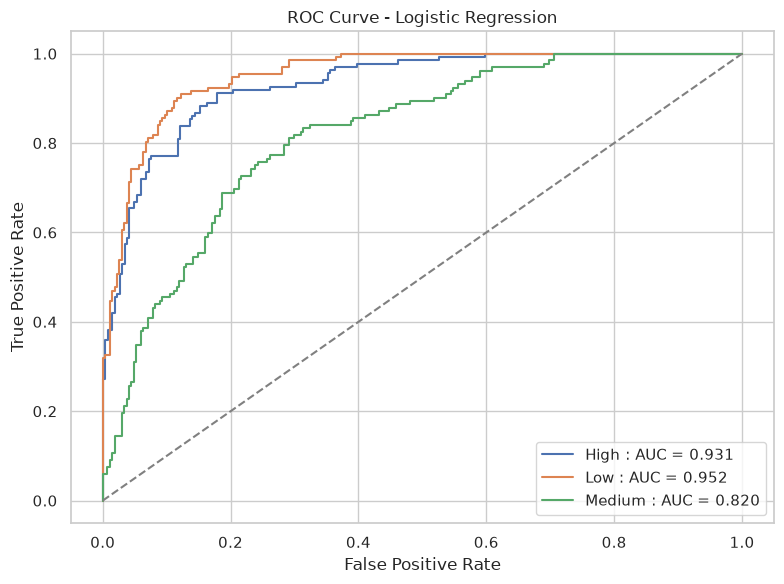

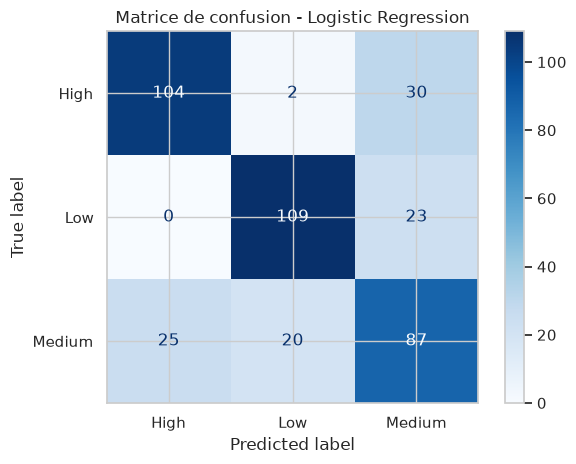

,model,Accuracy,Precision,Recall,F1-score,ROC_AUC
0,Logistic Regression,0.75,0.75323,0.749851,0.75117,0.901385


In [23]:
test_result = evaluate_model(best_name, best_model, X_test, y_test, plot=True)

display(pd.DataFrame([test_result]))

### 4.4 - Analyser les erreurs

In [24]:
errors = error_analysis(best_model, X_test, y_test)

print("Nombre d'erreurs :", len(errors), "/", len(X_test))

display(errors.head(15))

Nombre d'erreurs : 100 / 400


,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Actual,Predicted
1427,19,Female,5,6.9,29.2,2.48,5.1,8.0,High,6.7,8.2,85.9,Yes,Average,No,Medium,Low
669,23,Male,4,NaN,23.1,2.49,5.7,7.8,Moderate,6.2,6.8,70.0,No,Average,No,Low,Medium
1592,22,Male,2,7.8,21.5,2.79,4.4,8.3,Moderate,9.5,7.5,93.9,No,Average,Yes,High,Medium
1074,23,Male,4,6.6,15.8,2.17,5.6,6.6,Moderate,5.2,8.0,87.9,No,Average,No,Low,Medium
961,24,Male,2,6.4,18.0,2.15,5.4,6.9,Low,9.0,9.3,76.2,Yes,Good,No,High,Medium
1803,18,Female,3,7.1,20.4,2.23,NaN,9.3,Moderate,8.0,5.8,82.7,No,Good,No,High,Medium
492,21,Male,4,6.6,28.4,3.15,6.7,9.7,Low,7.8,6.1,90.8,No,Poor,No,Medium,High
382,17,Female,2,8.7,20.4,2.82,5.3,4.1,Low,3.8,8.8,90.5,Yes,Poor,Yes,Medium,Low
1131,22,Male,1,6.5,7.4,1.95,6.6,10.6,Moderate,7.2,8.2,77.9,No,Poor,No,Medium,High
1807,22,Female,5,7.4,20.8,2.59,5.3,7.6,High,7.3,4.8,100.0,Yes,Poor,Yes,High,Medium


### 4.5 - Sauvegarder le pipeline complet

In [25]:
saved_path = save_model(best_model, MODEL_PATH)

print("Pipeline sauvegardé :", saved_path.resolve())

restored_model = load_model(saved_path)

print("Prédictions de vérification :", restored_model.predict(X_test.head(3)))

Pipeline sauvegardé : /home/hajjajihamza/Ycode/soutenance-croisee-brief-1/models/mental_health_pipeline.joblib
Prédictions de vérification : ['Low' 'High' 'Low']
